Iter 1: shift=0.013867
Iter 2: shift=0.011396
Iter 3: shift=0.008765
Iter 4: shift=0.007742
Iter 5: shift=0.006693
Iter 6: shift=0.005786
Iter 7: shift=0.005047
Iter 8: shift=0.004801
Iter 9: shift=0.004744
Iter 10: shift=0.003707
Iter 11: shift=0.003525
Iter 12: shift=0.003230
Iter 13: shift=0.002943
Iter 14: shift=0.002771
Iter 15: shift=0.002624


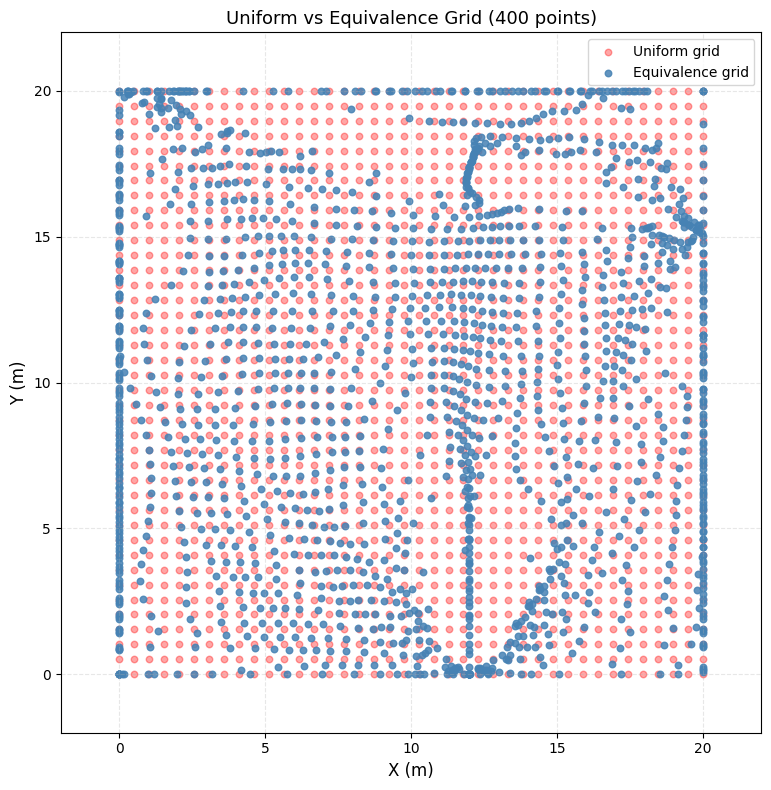

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd
from scipy.optimize import minimize

# 1. 系统参数

c = 3e8
fc = 2.4e9
wavelength = c / fc
d = wavelength / 2
M_antennas = 10


# 2. 导向向量（近场 ULA）
def array_manifold_vector(theta, r, M, d, wavelength):
    a = np.zeros(M, dtype=complex)
    for m in range(M):
        phase = -2j*np.pi*m*(d/wavelength)*np.sin(theta)
        phase += 1j*np.pi*(m**2)*(d**2)/(wavelength*r)*(np.cos(theta))**2
        a[m] = np.exp(phase)
    return a / np.linalg.norm(a)

# 3. 初始均匀网格

G = 1600
x_min, x_max = 0, 20
y_min, y_max = 0, 20
grid_size = int(np.sqrt(G))
x_uni = np.linspace(x_min, x_max, grid_size)
y_uni = np.linspace(y_min, y_max, grid_size)
X, Y = np.meshgrid(x_uni, y_uni)
initial_grid = np.column_stack((X.ravel(), Y.ravel()))[:G]


# 4. AP 坐标（文献图 2）

ap_positions = np.array([[0, 20], [20, 15], [12, 0]])

# 5. 工具函数

def cart2pol(grid, ap):
    dx = grid[:, 0] - ap[0]
    dy = grid[:, 1] - ap[1]
    r = np.sqrt(dx**2 + dy**2)
    theta = np.arctan2(dy, dx)
    return theta, r

def build_joint_dict(grid, ap_pos_list, M, d, wavelength):
    P = len(ap_pos_list)
    Psi_list = []
    for ap in ap_pos_list:
        theta, r = cart2pol(grid, ap)
        r = np.maximum(r, 1e-3)  # 防除零
        Psi_ap = np.zeros((M, grid.shape[0]), dtype=complex)
        for g in range(grid.shape[0]):
            Psi_ap[:, g] = array_manifold_vector(theta[g], r[g], M, d, wavelength)
        Psi_list.append(Psi_ap)
    return np.vstack(Psi_list)


# 6. 交替投影

max_iter = 15
tol = 1e-4
grid = initial_grid.copy()
N = grid.shape[0]

for it in range(max_iter):
    Psi = build_joint_dict(grid, ap_positions, M_antennas, d, wavelength)
    M_total = Psi.shape[0]

    PsiPsiH = Psi @ Psi.conj().T
    U, s, _ = svd(PsiPsiH, full_matrices=False)
    s_real = np.maximum(np.real(s), 0.0)
    s_inv = np.where(s_real > 1e-10, 1.0/np.sqrt(s_real), 0.0)
    PsiPsiH_inv = U @ np.diag(s_inv) @ U.conj().T
    S = (N / M_total) * PsiPsiH_inv @ Psi

    new_grid = np.zeros_like(grid)
    for n in range(N):
        target = S[:, n] / np.linalg.norm(S[:, n])
        def loss(p):
            x, y = p
            for ap in ap_positions:
                if np.abs(x - ap[0]) + np.abs(y - ap[1]) < 1e-3:
                    return 1e6
            psi = build_joint_dict(np.array([[x, y]]), ap_positions,
                                   M_antennas, d, wavelength)[:, 0]
            psi_norm = np.linalg.norm(psi)
            if psi_norm < 1e-10:
                return 1e6
            psi /= psi_norm
            return np.linalg.norm(target - psi)**2
        res = minimize(loss, grid[n], method='L-BFGS-B',
                       bounds=[(x_min, x_max), (y_min, y_max)])
        new_grid[n] = res.x

    shift = np.linalg.norm(new_grid - grid) / np.linalg.norm(grid)
    print(f"Iter {it+1}: shift={shift:.6f}")
    if shift < tol:
        break
    grid = new_grid


plt.figure(figsize=(8, 8))
plt.scatter(initial_grid[:, 0], initial_grid[:, 1],
            s=22, alpha=0.35, c='red', marker='o', label='Uniform grid')
plt.scatter(grid[:, 0], grid[:, 1],
            s=22, alpha=0.85, c='steelblue', marker='o', label='Equivalence grid')

#  关键：留白！把范围故意放大
padding = 2.0
plt.xlim(x_min - padding, x_max + padding)
plt.ylim(y_min - padding, y_max + padding)

plt.xlabel('X (m)', fontsize=12)
plt.ylabel('Y (m)', fontsize=12)
plt.title('Uniform vs Equivalence Grid (400 points)', fontsize=13)
plt.legend(loc='upper right')
plt.grid(True, ls='--', alpha=0.3)
plt.gca().set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()